In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
GPU available: False


In [2]:

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)


100%|██████████| 26.4M/26.4M [00:01<00:00, 14.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 230kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.32MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.5MB/s]

Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])


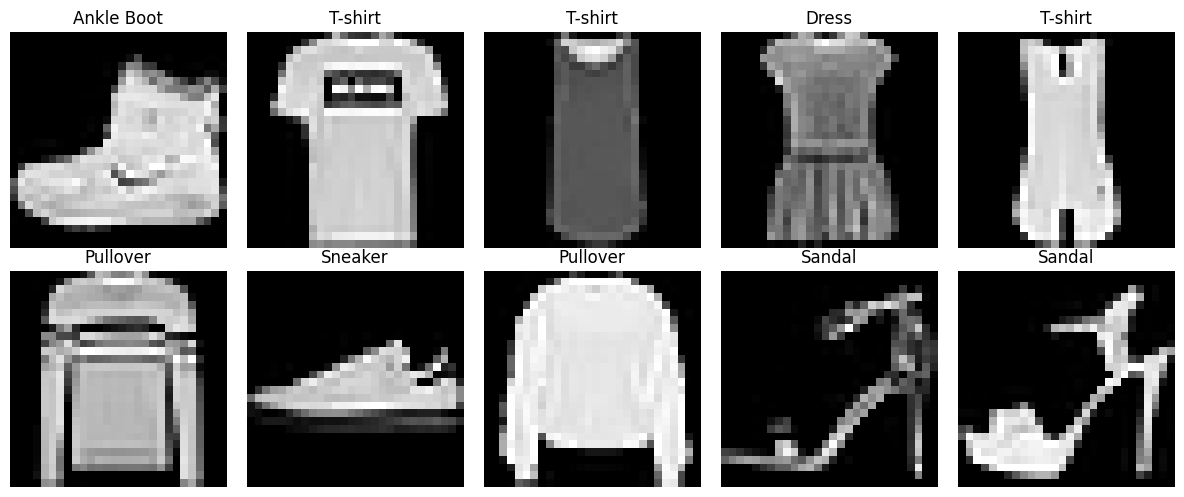

In [3]:

classes = [
    "T-shirt", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle Boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

from torch.utils.data import random_split

# กำหนด Seed เพื่อให้แบ่งข้อมูลได้เหมือนเดิมทุกครั้ง
generator = torch.Generator().manual_seed(42)

# แบ่ง Training Dataset เป็น 48,000 และ 12,000
train_subset, val_subset = random_split(
    train_dataset,
    [48000, 12000],
    generator=generator
)

# Test Dataset ใช้ชุดเดิม 10,000 ภาพ
test_subset = test_dataset

print("Train:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_subset))


Train: 48000
Validation: 12000
Test: 10000


In [5]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 750
Validation batches: 188
Test batches: 157


In [6]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
First 10 labels: [0, 1, 3, 0, 7, 3, 1, 2, 2, 1]


In [9]:

import torch.nn as nn
import torch.nn.functional as F

class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()

        # Convolution layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Pooling
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


In [10]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = FashionCNN().to(device)

print("Device:", device)
print(model)


Device: cpu
FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [11]:

images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Parameters: 421642


In [12]:
import torch.optim as optim

# วัดความผิดพลาดของโมเดล
criterion = nn.CrossEntropyLoss()

# วิธีปรับน้ำหนักของโมเดล
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [13]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # ล้างค่าการคำนวณ Gradient รอบก่อน
        optimizer.zero_grad()

        # ให้โมเดลทำนาย
        outputs = model(images)

        # คำนวณความผิดพลาด
        loss = criterion(outputs, labels)

        # คำนวณ Gradient
        loss.backward()

        # ปรับน้ำหนักโมเดล
        optimizer.step()

        # เก็บค่า Loss
        running_loss += loss.item()

        # ตรวจสอบจำนวนที่ทำนายถูก
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [14]:
def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            # ให้โมเดลทำนาย
            outputs = model(images)

            # คำนวณความผิดพลาด
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            # ตรวจสอบจำนวนที่ทำนายถูก
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [15]:
EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

In [16]:
for epoch in range(EPOCHS):

    # ฝึกโมเดล
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # ตรวจสอบโมเดล
    val_loss, val_acc = validate_one_epoch(
        model, val_loader, criterion, device
    )

    # บันทึกผลลัพธ์
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%")
    print("-" * 50)

Epoch [1/10]
Train Loss: 0.5739 | Train Accuracy: 79.04%
Val Loss: 0.3784 | Val Accuracy: 86.40%
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.3672 | Train Accuracy: 86.77%
Val Loss: 0.3118 | Val Accuracy: 88.48%
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.3118 | Train Accuracy: 88.67%
Val Loss: 0.2719 | Val Accuracy: 90.03%
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.2794 | Train Accuracy: 89.94%
Val Loss: 0.2542 | Val Accuracy: 90.67%
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.2572 | Train Accuracy: 90.67%
Val Loss: 0.2412 | Val Accuracy: 91.12%
--------------------------------------------------
Epoch [6/10]
Train Loss: 0.2352 | Train Accuracy: 91.33%
Val Loss: 0.2412 | Val Accuracy: 91.25%
--------------------------------------------------
Epoch [7/10]
Train Loss: 0.2177 | Train Accuracy: 91.98%
Val Loss: 0.2335 | Val Accuracy: 91.48%
---------------

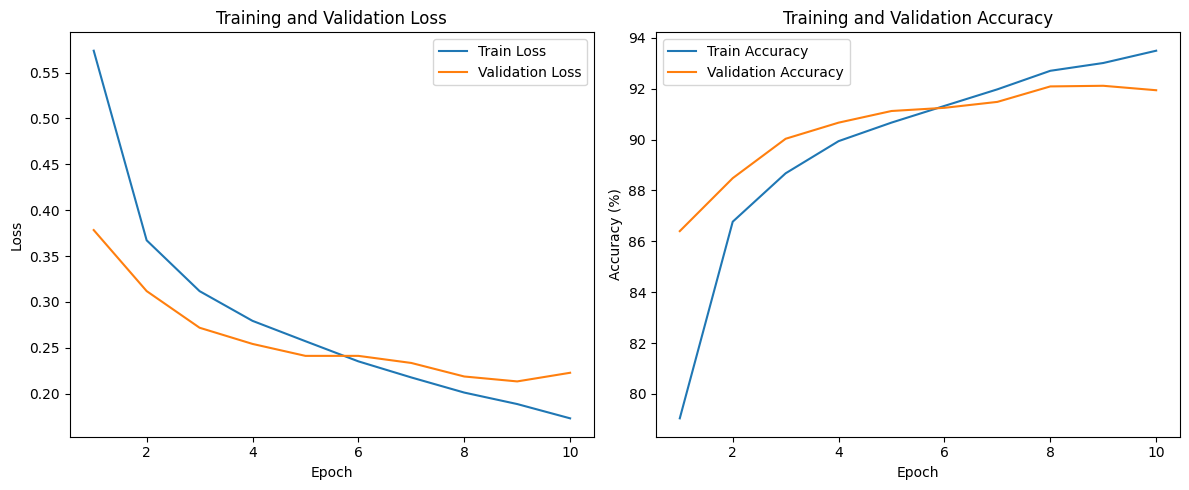

In [17]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# กราฟ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

# กราฟ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_accuracy"], label="Train Accuracy")
plt.plot(epochs_range, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
torch.save(
    model.state_dict(),
    "fashion_cnn.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [19]:
import os

print("File exists:", os.path.exists("fashion_cnn.pth"))
print("File size:", os.path.getsize("fashion_cnn.pth") / 1024, "KB")

File exists: True
File size: 1650.5673828125 KB


In [20]:
# สร้างโมเดลใหม่
test_model = FashionCNN().to(device)

# โหลดน้ำหนักที่บันทึกไว้
test_model.load_state_dict(
    torch.load("fashion_cnn.pth", map_location=device)
)

test_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [21]:
correct = 0
total = 0
test_loss = 0.0

test_model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = test_model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
test_loss = test_loss / len(test_loader)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct Predictions: {correct}/{total}")

Test Loss: 0.2460
Test Accuracy: 91.35%
Correct Predictions: 9135/10000


In [22]:
from sklearn.metrics import classification_report, confusion_matrix

all_predictions = []
all_labels = []

test_model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = test_model(images)
        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().tolist())
        all_labels.extend(labels.tolist())

In [23]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    digits=4
))

              precision    recall  f1-score   support

     T-shirt     0.8720    0.8580    0.8649      1000
     Trouser     0.9939    0.9790    0.9864      1000
    Pullover     0.7844    0.9350    0.8531      1000
       Dress     0.9072    0.9380    0.9223      1000
        Coat     0.8754    0.8360    0.8552      1000
      Sandal     0.9899    0.9810    0.9854      1000
       Shirt     0.8086    0.6760    0.7364      1000
     Sneaker     0.9569    0.9760    0.9663      1000
         Bag     0.9812    0.9900    0.9856      1000
  Ankle Boot     0.9718    0.9660    0.9689      1000

    accuracy                         0.9135     10000
   macro avg     0.9141    0.9135    0.9125     10000
weighted avg     0.9141    0.9135    0.9125     10000



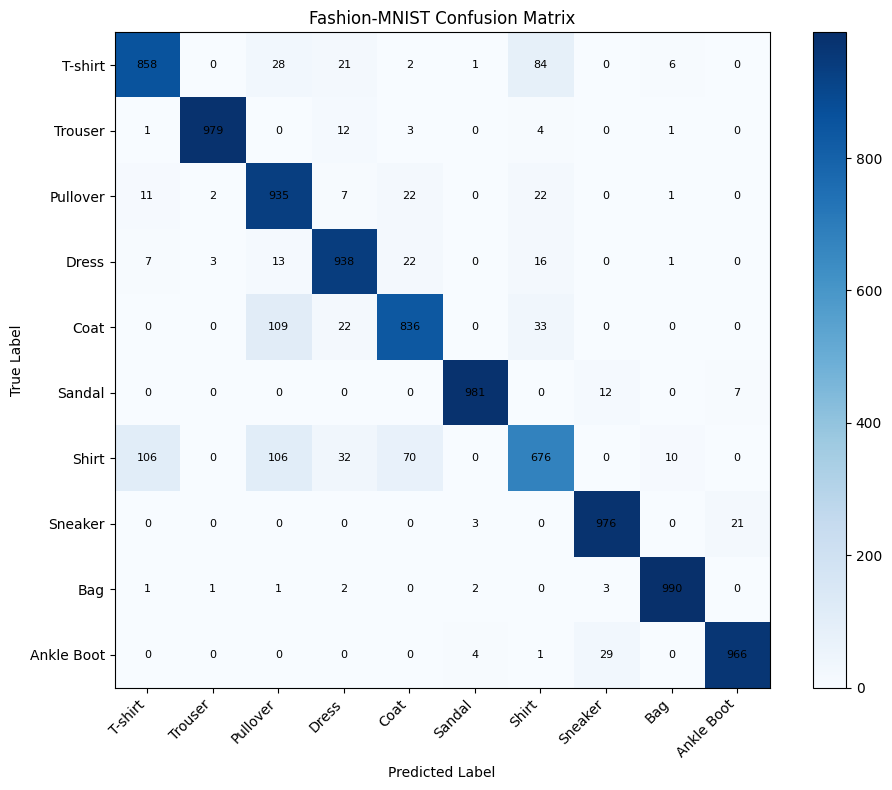

In [24]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10), classes, rotation=45, ha="right")
plt.yticks(range(10), classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fashion-MNIST Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="black", fontsize=8)

plt.tight_layout()
plt.show()

Total wrong predictions: 865


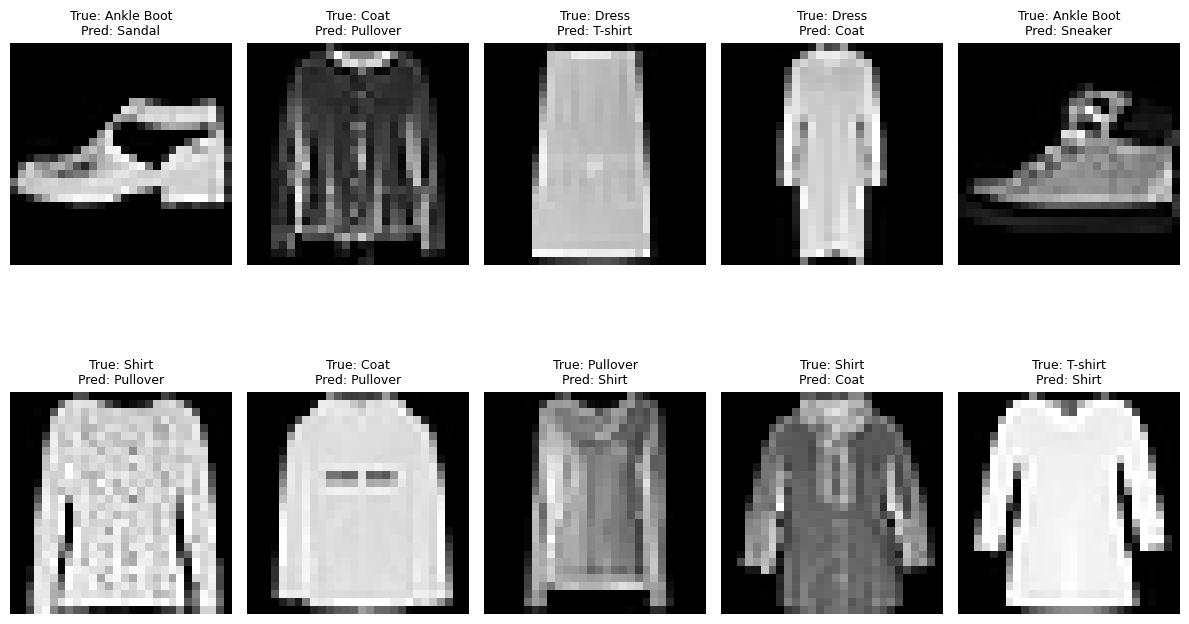

In [25]:
wrong_indices = [
    i for i in range(len(all_labels))
    if all_labels[i] != all_predictions[i]
]

print("Total wrong predictions:", len(wrong_indices))

plt.figure(figsize=(12, 8))

for i in range(min(10, len(wrong_indices))):

    idx = wrong_indices[i]

    image, label = test_dataset[idx]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")

    plt.title(
        f"True: {classes[label]}\nPred: {classes[all_predictions[idx]]}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
from collections import Counter

train_labels = [
    train_dataset[index][1]
    for index in train_subset.indices
]

label_counts = Counter(train_labels)

most_common_class, most_common_count = label_counts.most_common(1)[0]

print("Most common class:", classes[most_common_class])
print("Number of images:", most_common_count)

Most common class: Sneaker
Number of images: 4866


In [27]:
baseline_accuracy = 100 * most_common_count / len(train_labels)

print(f"Baseline Accuracy: {baseline_accuracy:.2f}%")
print(f"CNN Test Accuracy: {test_accuracy:.2f}%")
print(f"Improvement: {test_accuracy - baseline_accuracy:.2f} percentage points")

Baseline Accuracy: 10.14%
CNN Test Accuracy: 91.35%
Improvement: 81.21 percentage points
